# Лабораторная работа: кто из хозяев Airbnb в Афинах — Superhost?

Датасет: [Inside Airbnb, Athens](https://insideairbnb.com/get-the-data/) (снимок сентября 2026), файл `listings.csv.gz`.

## 0. Постановка задачи

Есть данные о 15 134 объявлениях Airbnb в Афинах: хозяин (стаж, число объявлений), жильё (тип, район,
вместимость, удобства, цена), правила бронирования, занятость календаря, отзывы и оценки гостей — всего 90
столбцов. Для каждого объявления известно, является ли его хозяин **суперхостом** (`host_is_superhost`). Это
статус, который Airbnb присваивает «образцовым» хозяевам: средняя оценка ≥ 4.8, не меньше 10 проживаний за год,
отмены < 1 %, ответ на ≥ 90 % сообщений.

Задача: по характеристикам объявления и хозяина предсказать, является ли хозяин суперхостом. Это задача
**бинарной классификации** (обучение с учителем):

- объект $x$ — описание объявления (≈ 50 признаков разных типов),
- ответ $y \in \{0, 1\}$: $1$ — суперхост, $0$ — нет.

Положительным классом выбран «суперхост». Практический смысл задачи — подсказать гостю, у какого хозяина,
скорее всего, будет образцовый сервис. Пообещать гостю образцового хозяина, которым тот не является (ошибка
1-го рода, ложноположительная), хуже, чем не отметить настоящего суперхоста (ошибка 2-го рода).

Важные особенности:

- Два официальных критерия (доля ответов на сообщения и доля отмен) в снимке полностью отсутствуют
  (`host_response_rate`, `host_acceptance_rate` пусты), поэтому модель восстанавливает статус по косвенным
  признакам.
- **Метка принадлежит хозяину, а не объявлению.** У одного хозяина бывает больше двухсот объявлений, и у всех
  одна и та же метка. Это учитываем при разбиении на обучающую и тестовую выборки.

In [1]:
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

## 1. Чтение данных

In [2]:
data_raw = pd.read_csv("listings.csv.gz", low_memory=False)
data_raw.shape

(15134, 90)

In [3]:
data_raw.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,25358481,https://www.airbnb.com/rooms/25358481,20260922161635,2026-09-24,NaN,*The Athens Green Apt*,Modern 🎨 Cozy 25 sq.m. ground floor flat🌼Fully...,NaN,https://a0.muscache.com/pictures/a354ac74-4bb7...,434487,https://www.airbnb.com/users/show/434487,1462518367119898086,https://www.airbnb.com/users/profile/146251836...,Yiorgos,NaN,15,6,8,10,"Palaio Faliro, Greece","The super traveller!!\r\nI am from Athens,Gree...",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/1ce91...,NaN,2,NaN,NaN,t,t,NaN,ΝΕΟΣ ΚΟΣΜΟΣ,NaN,37.95520,23.71741,Entire rental unit,Entire home/apt,2,NaN,1.5 baths,1.0,1.0,"[""Stove"", ""Heating"", ""Hair dryer"", ""Dishes and...",$60.00,2026-10-02,2026-10-03,60.0,60.00,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""...",1.0,1125.0,1.0,3.0,1125.0,1125.0,2.1,1125.0,NaN,t,17,47,77,347,2026-09-24,454,29,3,86,46,174,10440.0,2018-06-29,2026-09-03,4.94,4.95,4.88,4.98,4.99,4.76,4.86,00000109380,NaN,2,2,0,0,4.52
1,27262,https://www.airbnb.com/rooms/27262,20260922161635,2026-09-24,previous scrape,"AQA-No7, Great mattress, high speed internet",THE MATTRESS - KING KOIL - Camden Luxury 160x2...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,37177,https://www.airbnb.com/users/show/37177,1462507296852902494,https://www.airbnb.com/users/profile/146250729...,Emmanouil,NaN,17,0,15,8,"Athens, Greece",Athens Quality Apartments is a company started...,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/859c1...,NaN,4,NaN,NaN,t,t,NaN,ΑΜΠΕΛΟΚΗΠΟΙ,NaN,37.98924,23.76500,Entire rental unit,Entire home/apt,2,NaN,1 bath,1.0,1.0,"[""Dedicated workspace"", ""Coffee maker"", ""Hair ...",NaN,NaN,NaN,NaN,NaN,NaN,1.0,1125.0,1.0,1.0,1125.0,1125.0,1.0,1125.0,NaN,t,0,0,0,0,2026-09-24,29,0,0,0,0,0,NaN,2012-09-21,2024-11-18,4.86,4.89,4.90,4.86,4.97,4.75,4.71,00002433111,NaN,1,1,0,0,0.17
2,33945,https://www.airbnb.com/rooms/33945,20260922161635,2026-09-24,NaN,Spacious Cosy aprtm very close to Metro!,Apartment located near metro station. Safe nei...,NaN,https://a0.muscache.com/pictures/1a7a1026-f5f1...,146553,https://www.airbnb.com/users/show/146553,1462510025477328034,https://www.airbnb.com/users/profile/146251002...,Katerina,NaN,16,3,15,8,Greece,"Kind, respectful, generous and giving",NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/4cfe0...,NaN,1,NaN,NaN,t,t,NaN,ΑΓΙΟΣ ΝΙΚ

In [4]:
data_raw.info(verbose=False)
empty = [c for c in data_raw.columns if data_raw[c].isnull().all()]
print(len(empty), "полностью пустых столбцов:", empty)

<class 'pandas.DataFrame'>
RangeIndex: 15134 entries, 0 to 15133
Columns: 90 entries, id to reviews_per_month
dtypes: float64(37), int64(24), str(29)
memory usage: 10.4 MB
14 полностью пустых столбцов: ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'instant_bookable']


Столбцы по смыслу делятся на группы:

| Группа | Столбцы | Что делаем |
| --- | --- | --- |
| Служебные | `id`, `listing_url`, `scrape_id`, `last_scraped`, `source`, `calendar_last_scraped`, `picture_url`, `host_url`, `host_profile_*`, `host_picture_url` | удаляем |
| Тексты | `name`, `description`, `host_name`, `host_about`, `host_location` | удаляем (kNN не работает с текстом) |
| Хозяин | `host_listings_count`, `calculated_host_listings_count*`, `hosts_time_as_host_*`, `hosts_time_as_user_*`, `host_has_profile_pic`, `host_identity_verified` | стаж годы + месяцы → месяцы |
| Расположение | `latitude`, `longitude`, `neighbourhood_cleansed` | |
| Жильё | `room_type`, `property_type`, `accommodates`, `bedrooms`, `beds`, `bathrooms_text`, `amenities` | ванные → число + «общая ванная»; список удобств → их количество |
| Цена | `price`, `price_quote_*` | `"$60.00"` → число; `price_quote_*` повторяют цену — удаляем |
| Бронирование | `minimum_nights`, `maximum_nights` и 6 их вариантов, `availability_30/60/90/365/eoy`, `has_availability` | |
| Отзывы | `number_of_reviews`, `_ltm`, `_l30d`, `_ly`, `reviews_per_month`, `first_review`, `last_review`, `review_scores_*` (7 оценок) | даты → «сколько дней назад» |
| Активность | `estimated_occupancy_l365d`, `estimated_revenue_l365d` | |
| Лицензия | `license` (12 651 разный номер) | → категория `has` / `exempt` / `none` |
| Идентификатор хозяина | `host_id` | в признаки не берём, нужен для разбиения |
| **Целевая** | `host_is_superhost` | |

In [5]:
for c in ["room_type", "property_type", "neighbourhood_cleansed", "host_has_profile_pic",
          "host_identity_verified", "has_availability", "bathrooms_text", "license"]:
    print(f"{c:25s}", data_raw[c].nunique(), sorted(data_raw[c].dropna().unique())[:6])

room_type                 4 ['Entire home/apt', 'Hotel room', 'Private room', 'Shared room']
property_type             42 ['Boat', 'Camper/RV', 'Casa particular', 'Castle', 'Cycladic home', 'Entire condo']
neighbourhood_cleansed    44 ['1Ο ΝΕΚΡΟΤΑΦΕΙΟ', 'ΑΓΙΟΣ ΕΛΕΥΘΕΡΙΟΣ', 'ΑΓΙΟΣ ΚΩΝΣΤΑΝΤΙΝΟΣ-ΠΛΑΤΕΙΑ ΒΑΘΗΣ', 'ΑΓΙΟΣ ΝΙΚΟΛΑΟΣ', 'ΑΚΑΔΗΜΙΑ ΠΛΑΤΩΝΟΣ', 'ΑΚΡΟΠΟΛΗ']
host_has_profile_pic      2 ['f', 't']
host_identity_verified    2 ['f', 't']
has_availability          2 ['f', 't']
bathrooms_text            32 ['0 baths', '0 shared baths', '1 bath', '1 private bath', '1 shared bath', '1.5 baths']
license                   12651 ['0000000', '00000000000', '00000000423', '00000000647', '00000000839', '00000001882']


### Нет ли среди признаков «подсказки» ответа?

В датасете нет столбцов, вычисляемых из статуса суперхоста (балла, грейда и т. п.). Ближе всего к определению
статуса — средняя оценка гостей (критерий «≥ 4.8»). Проверим, не определяет ли она ответ:

In [6]:
target = (data_raw["host_is_superhost"] == "t").astype(int)
rating_ok = pd.cut(data_raw["review_scores_rating"], [0, 4.8 - 1e-9, 5], labels=["< 4.8", "≥ 4.8"])
pd.crosstab(rating_ok.cat.add_categories("нет оценки").fillna("нет оценки"), target,
            margins=True, normalize="index").round(3)

host_is_superhost,0,1
review_scores_rating,,
< 4.8,0.673,0.327
≥ 4.8,0.359,0.641
нет оценки,0.763,0.237
All,0.506,0.494


Среди объявлений с оценкой ≥ 4.8 суперхостов 64 %, а среди объявлений с оценкой ниже 4.8 их всё равно 33 %. Статус
считается по всем объявлениям хозяина за год вместе с другими критериями, поэтому оценка конкретного объявления
ответ не определяет. Утечки нет, все признаки можно использовать.

In [7]:
snapshot = pd.to_datetime(data_raw["last_scraped"]).max()

numerical_columns = [
    "host_listings_count", "calculated_host_listings_count", "calculated_host_listings_count_entire_homes",
    "calculated_host_listings_count_private_rooms", "calculated_host_listings_count_shared_rooms",
    "latitude", "longitude", "accommodates", "bedrooms", "beds",
    "minimum_nights", "maximum_nights", "minimum_minimum_nights", "maximum_minimum_nights",
    "minimum_maximum_nights", "maximum_maximum_nights", "minimum_nights_avg_ntm", "maximum_nights_avg_ntm",
    "availability_30", "availability_60", "availability_90", "availability_365", "availability_eoy",
    "number_of_reviews", "number_of_reviews_ltm", "number_of_reviews_l30d", "number_of_reviews_ly",
    "estimated_occupancy_l365d", "estimated_revenue_l365d",
    "review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness", "review_scores_checkin",
    "review_scores_communication", "review_scores_location", "review_scores_value", "reviews_per_month",
]
data = data_raw[numerical_columns].copy()

data["host_months"] = data_raw["hosts_time_as_host_years"] * 12 + data_raw["hosts_time_as_host_months"]
data["user_months"] = data_raw["hosts_time_as_user_years"] * 12 + data_raw["hosts_time_as_user_months"]
data["price"] = data_raw["price"].str.replace(r"[$,]", "", regex=True).astype(float)
baths = data_raw["bathrooms_text"].str.lower()
data["bathrooms"] = baths.str.extract(r"(\d+\.?\d*)")[0].astype(float)
data.loc[baths.str.contains("half", na=False), "bathrooms"] = 0.5
data["n_amenities"] = data_raw["amenities"].map(lambda s: len(json.loads(s)))
data["days_first_review"] = (snapshot - pd.to_datetime(data_raw["first_review"])).dt.days
data["days_last_review"] = (snapshot - pd.to_datetime(data_raw["last_review"])).dt.days
numerical_columns += ["host_months", "user_months", "price", "bathrooms", "n_amenities",
                      "days_first_review", "days_last_review"]

data["room_type"] = data_raw["room_type"]
data["property_type"] = data_raw["property_type"]
data["neighbourhood"] = data_raw["neighbourhood_cleansed"]
data["license"] = np.select([data_raw["license"].isna(), data_raw["license"].str.lower() == "exempt"],
                            ["none", "exempt"], "has")
data["host_has_profile_pic"] = data_raw["host_has_profile_pic"]
data["host_identity_verified"] = data_raw["host_identity_verified"]
data["has_availability"] = data_raw["has_availability"]
data["bath_shared"] = np.where(baths.str.contains("shared", na=False), "t", "f")
categorical_columns = ["room_type", "property_type", "neighbourhood", "license",
                       "host_has_profile_pic", "host_identity_verified", "has_availability", "bath_shared"]

y_all = target
host_id = data_raw["host_id"]
print(data.shape, " количественных:", len(numerical_columns), " категориальных:", len(categorical_columns))
y_all.value_counts(normalize=True).rename({0: "не суперхост (0)", 1: "суперхост (1)"})

(15134, 52)

  количественных: 44  категориальных: 8


host_is_superhost
не суперхост (0)    0.50555
суперхост (1)       0.49445
Name: proportion, dtype: float64

## 2. Разбиение данных на обучающую и тестовую выборки

Разбиваем до любого анализа и предобработки. Все характеристики (квантили, медианы для пропусков, средние для
нормализации, списки категорий) считаем только по обучающей выборке, чтобы информация из теста не попала в модель.

Обычный `train_test_split` здесь не подходит:

In [8]:
print("хозяев:", host_id.nunique())
print("хозяев с разными метками в разных объявлениях:", (y_all.groupby(host_id).nunique() > 1).sum())
print("больше всего объявлений у одного хозяина:", host_id.value_counts().head(5).tolist())

хозяев: 5798
хозяев с разными метками в разных объявлениях: 0
больше всего объявлений у одного хозяина: [227, 150, 126, 104, 92]


У хозяина все объявления с одной меткой и почти одинаковыми «хозяйскими» признаками (стаж, число объявлений).
При случайном разбиении объявления одного хозяина попадут в обе части, и kNN будет «узнавать» хозяина по его же
объявлению в обучающей выборке, а ошибка на тесте окажется заниженной. Поэтому разбиваем **по хозяевам**
(`GroupShuffleSplit`): все объявления хозяина попадают целиком в одну из частей. В тест — 25 % хозяев.

In [9]:
from sklearn.model_selection import GroupShuffleSplit
train_pos, test_pos = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
                           .split(data, y_all, groups=host_id))
X_train_raw, X_test_raw = data.iloc[train_pos].copy(), data.iloc[test_pos].copy()
y_train, y_test = y_all.iloc[train_pos], y_all.iloc[test_pos]
groups_train = host_id.iloc[train_pos]
print(X_train_raw.shape, X_test_raw.shape)
print("общих хозяев:", len(set(groups_train) & set(host_id.iloc[test_pos])))
print("доля суперхостов: train = %.4f, test = %.4f" % (y_train.mean(), y_test.mean()))

(11052, 52) (4082, 52)
общих хозяев: 0
доля суперхостов: train = 0.4683, test = 0.5652


Доли суперхостов в выборках различаются (47 % и 57 %). При разбиении по хозяевам нельзя точно выровнять доли
(`stratify`): крупный хозяин со своими 150–227 объявлениями целиком попадает в одну из частей и заметно сдвигает
её состав.

## 3. Визуализация и описательные характеристики (по обучающей выборке)

In [10]:
X_train_raw[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
host_listings_count,11052.0,33.502986,92.340444,1.00000,2.00000,7.00000,29.000000,1.191000e+03
calculated_host_listings_count,11052.0,15.979732,24.367814,1.00000,1.00000,5.00000,19.000000,1.260000e+02
calculated_host_listings_count_entire_homes,11052.0,14.949511,23.986845,0.00000,1.00000,4.00000,17.000000,1.260000e+02
calculated_host_listings_count_private_rooms,11052.0,0.758777,3.397249,0.00000,0.00000,0.00000,0.000000,2.900000e+01
calculated_host_listings_count_shared_rooms,11052.0,0.007781,0.204760,0.00000,0.00000,0.00000,0.000000,6.000000e+00
latitude,11052.0,37.979758,0.012919,37.94972,37.96917,37.97838,37.986824,3.803035e+01
longitude,11052.0,23.731086,0.012362,23.70071,23.72375,23.72928,23.736178,2.377862e+01
accommodates,11052.0,3.736699,1.909731,1.00000,2.00000,4.00000,4.000000,1.600000e+01
bedrooms,11050.0,1.400633,0.870749,0.00000,1.00000,1.00000,2.000000,1.400000e+01
beds,10858.0,2.076349,1.377516,0.00000,1.00000,2.00000,3.000000,3.000000e+01


In [11]:
X_train_raw[categorical_columns].describe().T

,count,unique,top,freq
room_type,11052,4,Entire home/apt,10277
property_type,11052,37,Entire rental unit,7147
neighbourhood,11052,43,ΕΜΠΟΡΙΚΟ ΤΡΙΓΩΝΟ-ΠΛΑΚΑ,2365
license,11052,3,has,10549
host_has_profile_pic,11052,2,t,10689
host_identity_verified,11052,2,t,10846
has_availability,11022,2,t,11008
bath_shared,11052,2,f,10833


Распределения всех количественных признаков в двух классах. Гистограммы нормированы, чтобы классы было удобно
сравнивать. Для наглядности обрезаем 1 % самых больших значений.

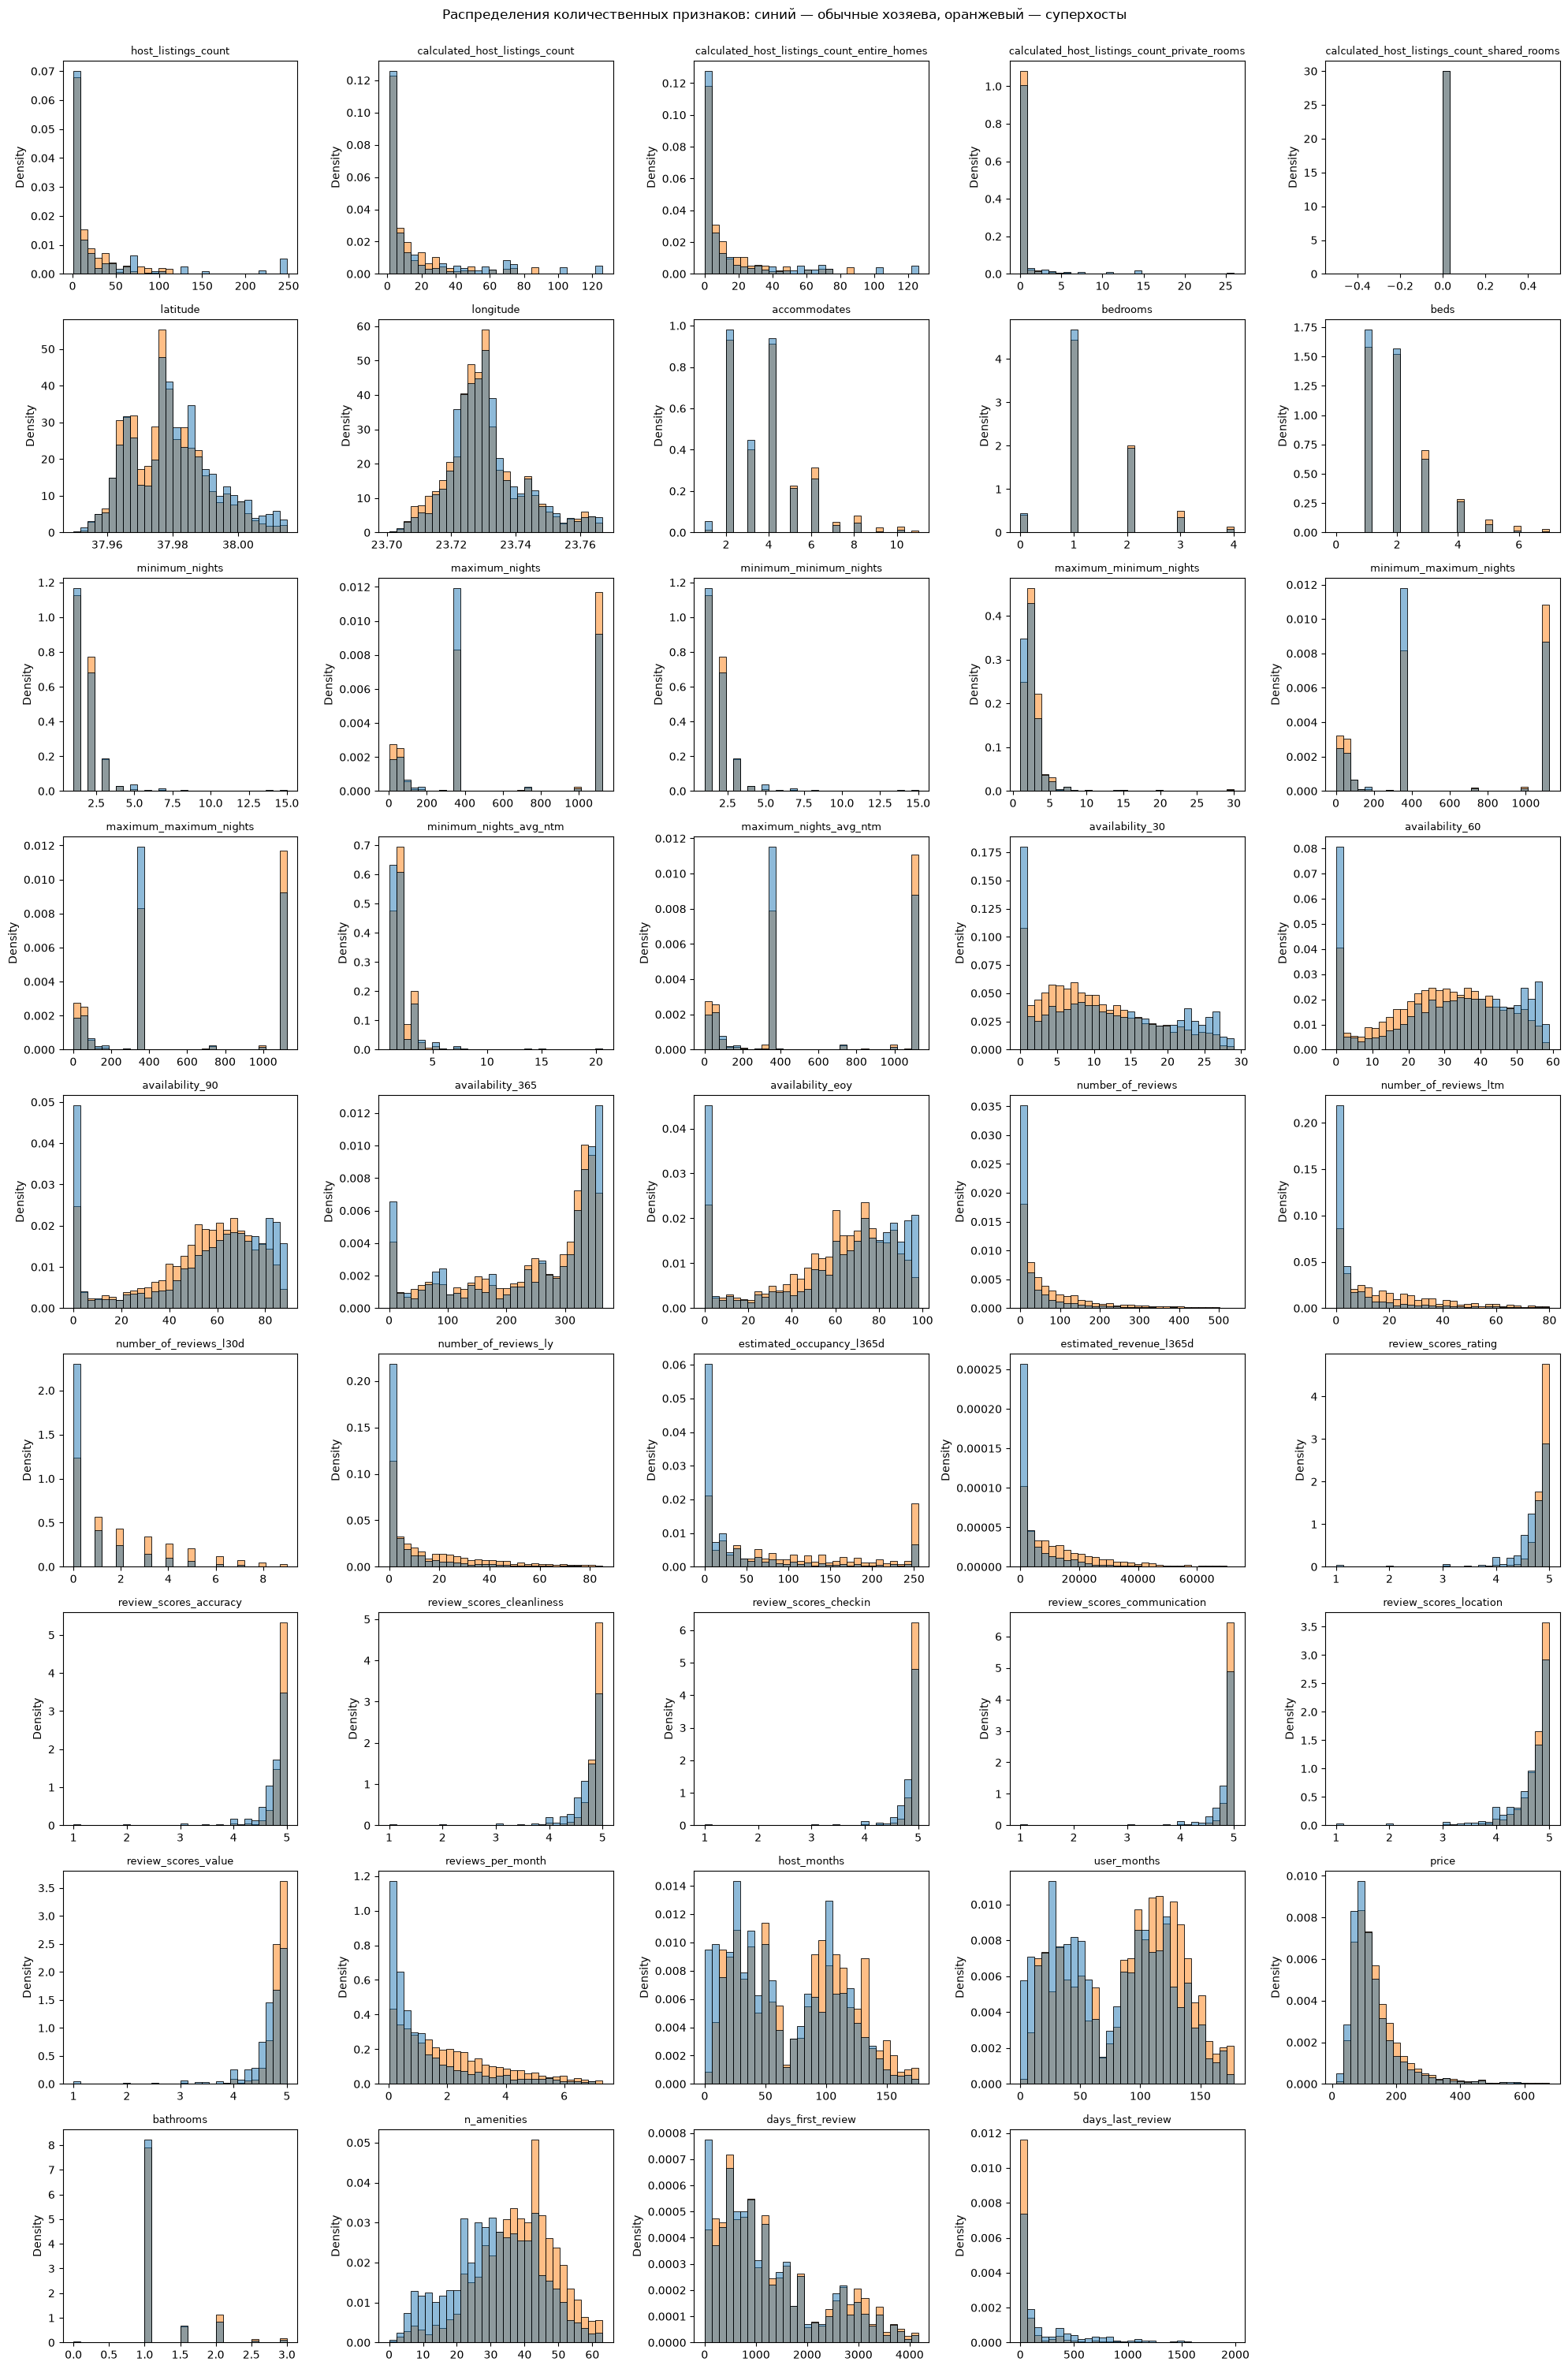

In [12]:
train_df = X_train_raw.assign(superhost=y_train.values)
fig, axes = plt.subplots(9, 5, figsize=(20, 30))
for ax, c in zip(axes.flat, numerical_columns):
    part = train_df[train_df[c] <= train_df[c].quantile(0.99)]
    sns.histplot(data=part, x=c, hue="superhost", bins=30, stat="density", common_norm=False, ax=ax, legend=False)
    ax.set_title(c, fontsize=9); ax.set_xlabel("")
for ax in axes.flat[len(numerical_columns):]:
    ax.axis("off")
fig.suptitle("Распределения количественных признаков: синий — обычные хозяева, оранжевый — суперхосты", y=1.0)
plt.tight_layout()

Доля суперхостов для каждого значения каждого категориального признака (для районов — только районы, где не
меньше 100 объявлений):

In [13]:
rate = []
for c in categorical_columns:
    s = train_df.groupby(c)["superhost"].agg(["mean", "size"])
    if c in ("neighbourhood", "property_type"):
        s = s[s["size"] >= 100]
    rate.append(pd.DataFrame({"признак": c, "значение": s.index, "доля суперхостов": s["mean"].values,
                              "кол-во": s["size"].values}))
rate = pd.concat(rate, ignore_index=True)
rate.style.background_gradient(subset=["доля суперхостов"], cmap="Reds", vmin=0, vmax=1) \
    .format({"доля суперхостов": "{:.3f}"})

,признак,значение,доля суперхостов,кол-во
0,room_type,Entire home/apt,0.482,10277
1,room_type,Hotel room,0.231,91
2,room_type,Private room,0.289,674
3,room_type,Shared room,0.600,10
4,property_type,Entire condo,0.576,2394
5,property_type,Entire home,0.469,311
6,property_type,Entire rental unit,0.452,7147
7,property_type,Entire serviced apartment,0.360,211
8,property_type,Private room in rental unit,0.252,242
9,property_type,Room in hotel,0.201,268


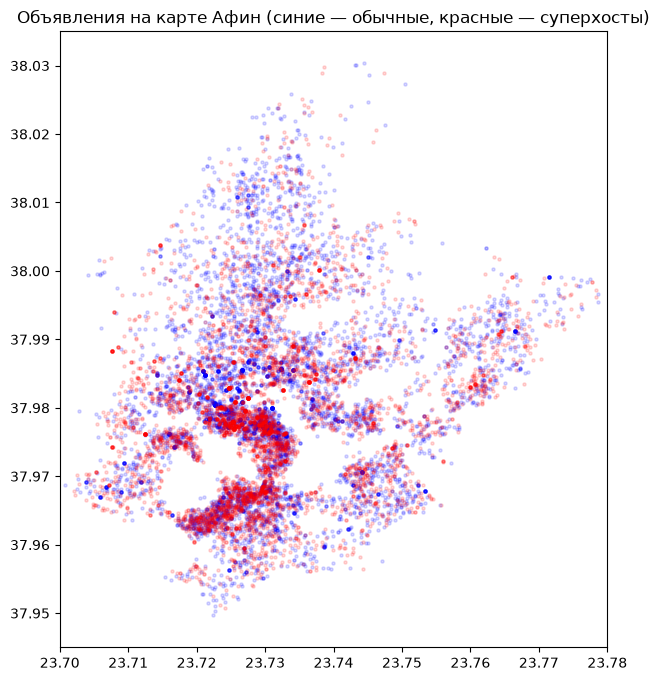

In [14]:
plt.figure(figsize=(8, 8))
for value, color in [(0, "b"), (1, "r")]:
    part = train_df[train_df["superhost"] == value]
    plt.scatter(part["longitude"], part["latitude"], color=color, alpha=0.15, s=5)
plt.xlim(23.70, 23.78); plt.ylim(37.945, 38.035)
plt.gca().set_aspect("equal")
plt.title("Объявления на карте Афин (синие — обычные, красные — суперхосты)")
pass

### Корреляционная матрица

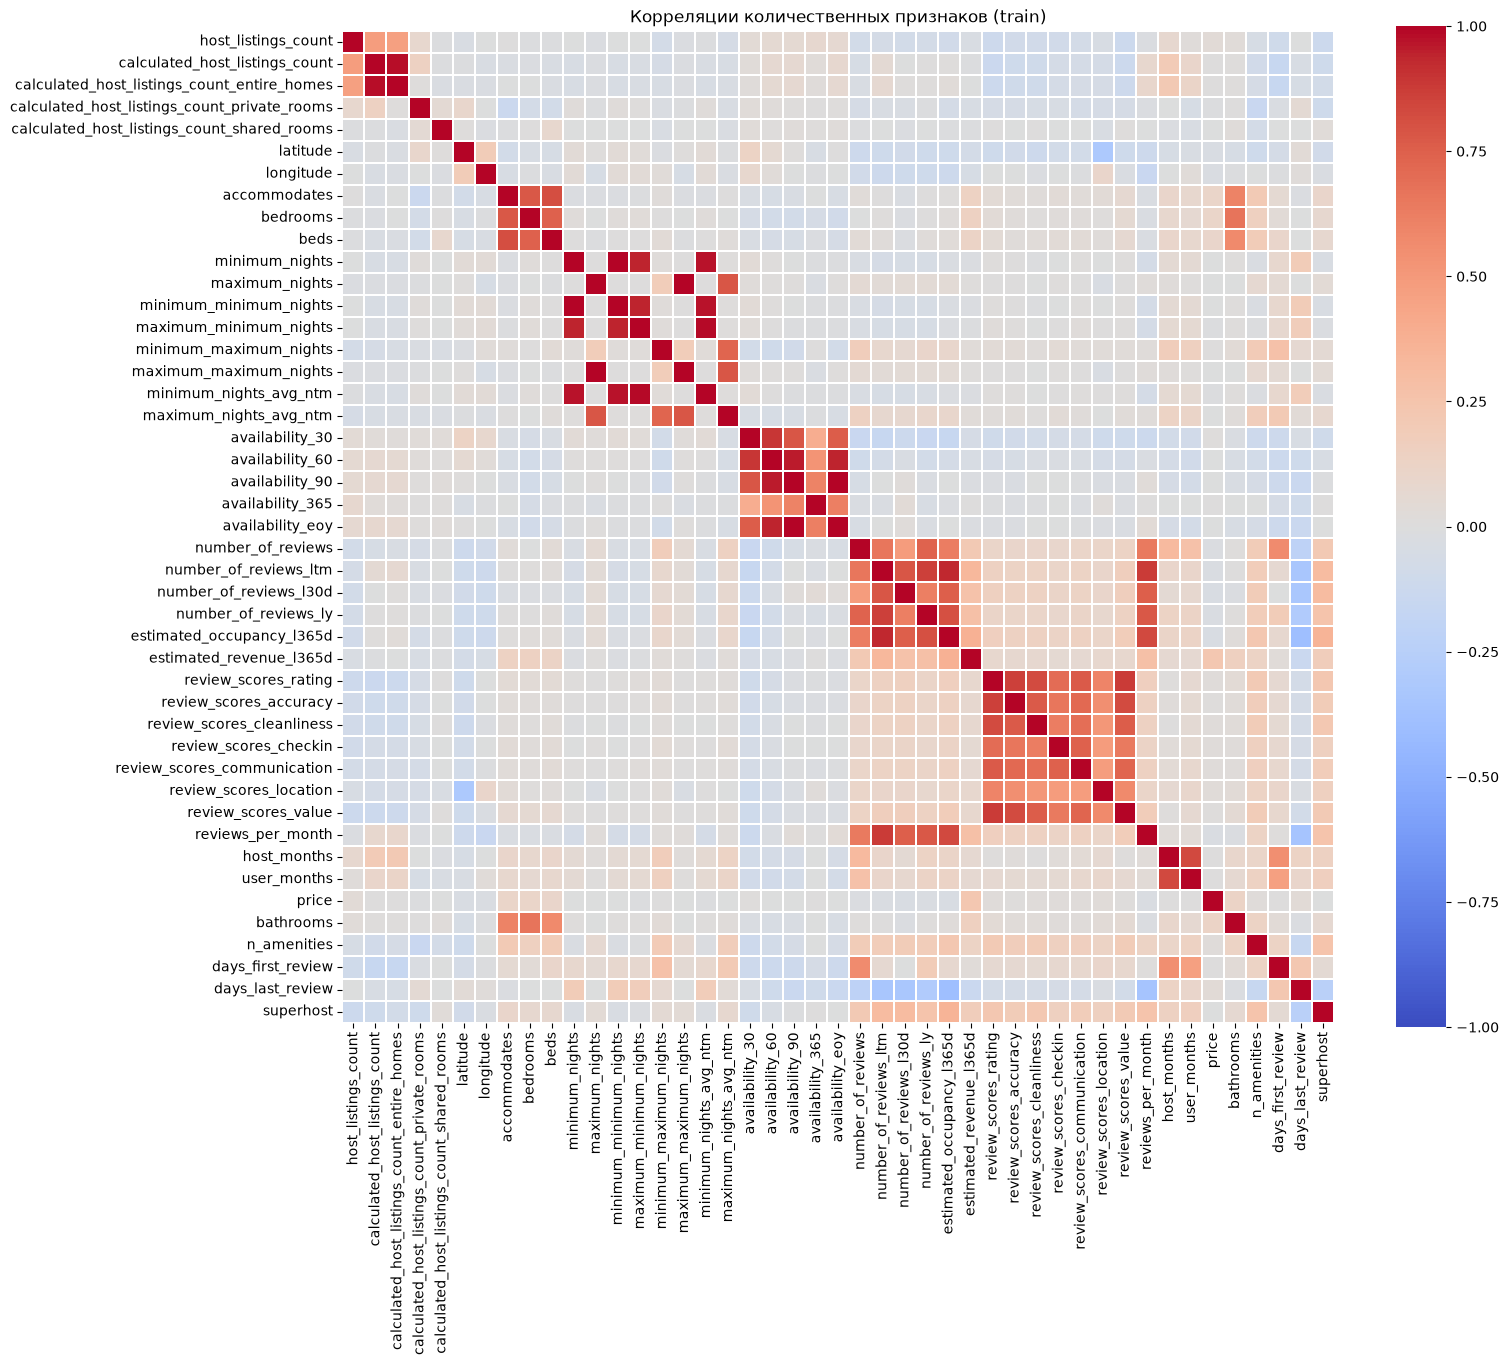

In [15]:
corr = train_df[numerical_columns + ["superhost"]].corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=.3)
plt.title("Корреляции количественных признаков (train)")
pass

In [16]:
corr["superhost"].drop("superhost").sort_values(key=abs, ascending=False).head(15)

estimated_occupancy_l365d      0.357223
number_of_reviews_ltm          0.311153
number_of_reviews_l30d         0.308219
number_of_reviews_ly           0.257001
n_amenities                    0.256556
reviews_per_month              0.254297
days_last_review              -0.236868
review_scores_rating           0.229196
review_scores_cleanliness      0.221716
number_of_reviews              0.217640
review_scores_value            0.204945
review_scores_accuracy         0.195111
review_scores_communication    0.180635
estimated_revenue_l365d        0.174102
user_months                    0.163791
Name: superhost, dtype: float64

In [17]:
c_abs = corr.drop(index="superhost", columns="superhost").abs()
pairs = (c_abs.where(np.triu(np.ones(c_abs.shape, dtype=bool), k=1)).stack().dropna()
         .sort_values(ascending=False))
pairs.head(15)

minimum_nights                  minimum_minimum_nights                         1.000000
maximum_nights                  maximum_maximum_nights                         1.000000
availability_90                 availability_eoy                               0.996092
maximum_minimum_nights          minimum_nights_avg_ntm                         0.987119
calculated_host_listings_count  calculated_host_listings_count_entire_homes    0.982484
minimum_minimum_nights          minimum_nights_avg_ntm                         0.970813
minimum_nights                  minimum_nights_avg_ntm                         0.970813
availability_60                 availability_90                                0.955989
minimum_minimum_nights          maximum_minimum_nights                         0.943828
minimum_nights                  maximum_minimum_nights                         0.943828
availability_60                 availability_eoy                               0.940924
number_of_reviews_ltm           

**Интерпретация.**

- Типичное объявление — целая квартира (93 %) на 4 гостей с 1 спальней, медианная цена 110 € за ночь. Хозяин
  на Airbnb около 5 лет (медиана 62 месяца), но половина объявлений принадлежит хозяевам, у которых 7 и
  больше объявлений: заметную часть рынка держат управляющие компании.
- У многих признаков длинный правый хвост: среднее намного больше медианы. Число объявлений хозяина — среднее
  33.5 при медиане 7 и максимуме 1 191. То же с числом отзывов, ценой, минимальным сроком, выручкой. Оценки
  гостей, наоборот, прижаты к верхней границе: медиана 4.87 из 5, длинный хвост влево.
- С тем, что хозяин — суперхост, сильнее всего связана **активность**:
  * расчётная занятость за год ($r = 0.36$);
  * отзывы за год и за последние 30 дней (0.31);
  * число отзывов в месяц (0.25).

  Затем **качество**: число удобств (0.26), оценки гостей (0.18–0.23). Отрицательно связаны давность последнего
  отзыва (−0.24) и число объявлений хозяина (−0.12).
- На гистограммах у не-суперхостов виден высокий пик в нуле у числа отзывов, занятости и свободных дней за
  30–90 дней. Это новые объявления без гостей или объявления с закрытым календарём. У суперхостов больше удобств,
  больше стаж, оценки ближе к 5.
- Цена, вместимость, число спален и координаты в двух классах распределены почти одинаково ($|r| < 0.1$). На карте
  суперхосты рассыпаны по всему центру, явной географической границы нет.
- По категориальным признакам доля суперхостов (у целых квартир 48 %) заметно ниже:
  * у отдельных комнат (29 %) и номеров в отелях (23 %);
  * у объявлений, освобождённых от лицензии (17 %);
  * у хозяев без фото (23 %) и с неподтверждённой личностью (10 %);
  * у объявлений с общей ванной (23 %).

  По районам доля меняется от 25 % до 60 %.
- Сильно коррелированные пары — почти дубликаты:
  * `minimum_nights` ≡ `minimum_minimum_nights` и `maximum_nights` ≡ `maximum_maximum_nights` ($r = 1$);
  * `availability_90` ~ `availability_eoy` (0.996);
  * два счётчика объявлений хозяина (0.98);
  * отзывы за год ~ расчётная занятость (0.94).
- Каждый отдельный признак связан с ответом слабо ($|r| \le 0.36$), на гистограммах классы сильно перекрываются.
  Безошибочно предсказать статус не получится, польза — от сочетания многих признаков.

## 4. Выбросы

Ищем значения, которые сильно выпадают из общей картины. Сначала посмотрим на ящики с усами и квантили, затем
проверим, нет ли невозможных значений.

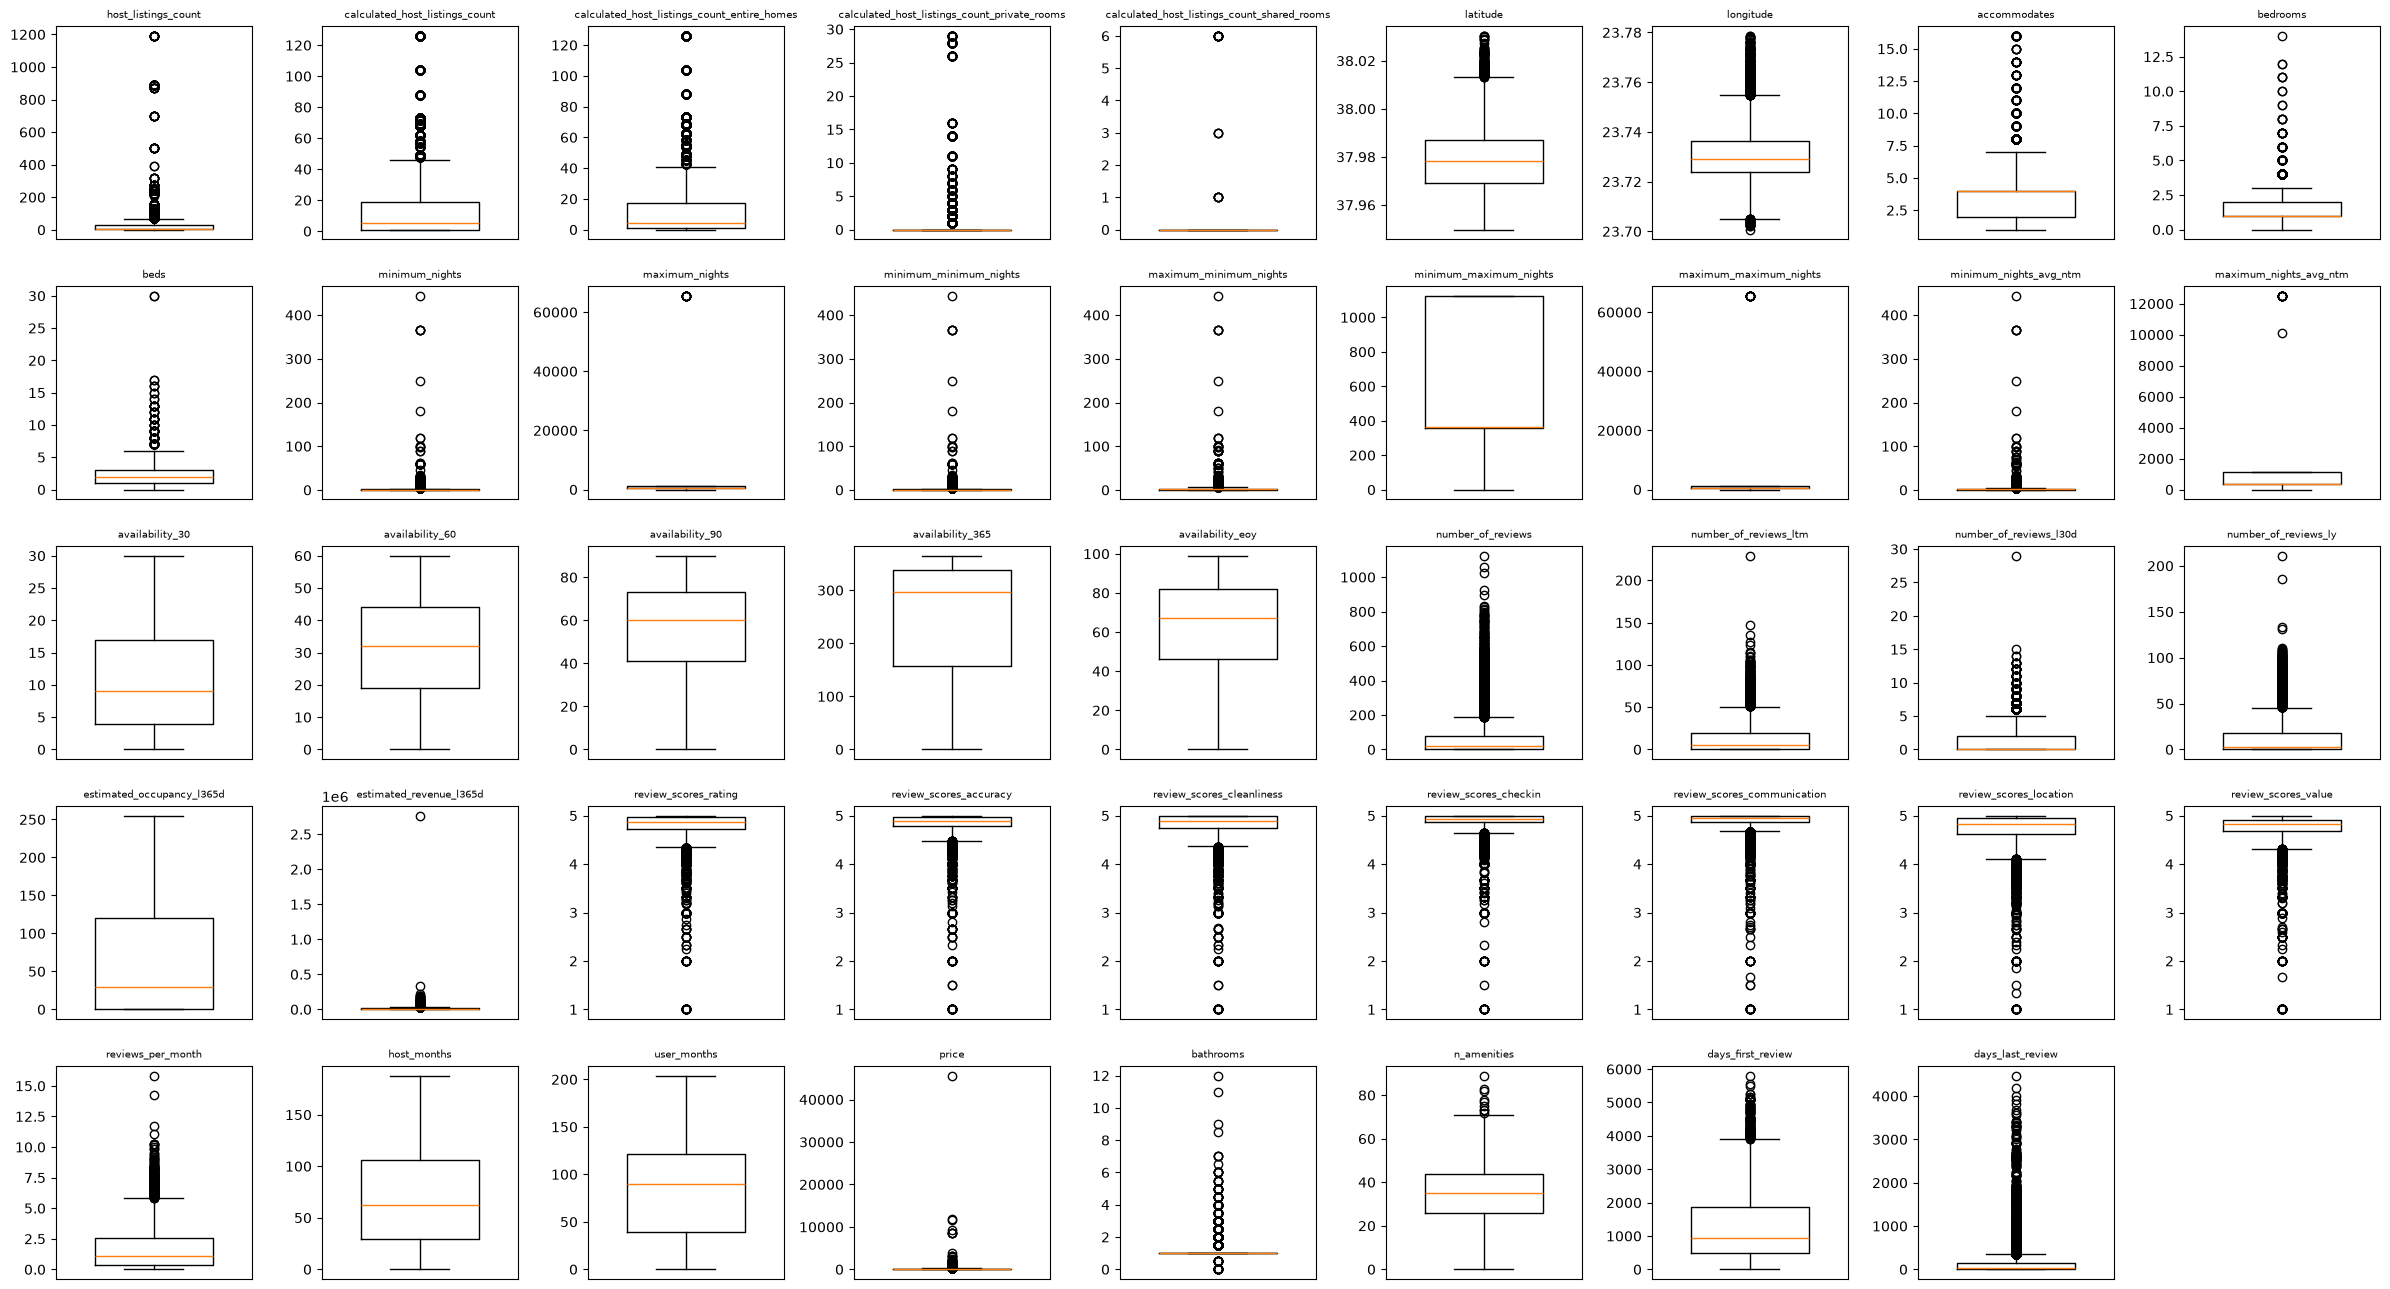

In [18]:
fig, axes = plt.subplots(5, 9, figsize=(24, 13))
for ax, c in zip(axes.flat, numerical_columns):
    ax.boxplot(X_train_raw[c].dropna(), widths=.6)
    ax.set_title(c, fontsize=7); ax.set_xticks([])
for ax in axes.flat[len(numerical_columns):]:
    ax.axis("off")
plt.tight_layout()

In [19]:
X_train_raw[numerical_columns].quantile([0, .005, .5, .995, 1]).T

,0.000,0.005,0.500,0.995,1.000
host_listings_count,1.00000,1.000000,7.00000,890.000000,1.191000e+03
calculated_host_listings_count,1.00000,1.000000,5.00000,126.000000,1.260000e+02
calculated_host_listings_count_entire_homes,0.00000,0.000000,4.00000,126.000000,1.260000e+02
calculated_host_listings_count_private_rooms,0.00000,0.000000,0.00000,28.000000,2.900000e+01
calculated_host_listings_count_shared_rooms,0.00000,0.000000,0.00000,0.000000,6.000000e+00
latitude,37.94972,37.955196,37.97838,38.018861,3.803035e+01
longitude,23.70071,23.705905,23.72928,23.770737,2.377862e+01
accommodates,1.00000,1.000000,4.00000,13.000000,1.600000e+01
bedrooms,0.00000,0.000000,1.00000,5.000000,1.400000e+01
beds,0.00000,1.000000,2.00000,8.000000,3.000000e+01


In [20]:
# правило 1.5 IQR для каждого признака
Q1 = X_train_raw[numerical_columns].quantile(.25)
Q3 = X_train_raw[numerical_columns].quantile(.75)
IQR = Q3 - Q1
outside = ((X_train_raw[numerical_columns] < Q1 - 1.5 * IQR) | (X_train_raw[numerical_columns] > Q3 + 1.5 * IQR)).sum()
outside[outside > 0].sort_values(ascending=False).head(15)

bathrooms                                       2226
days_last_review                                1751
host_listings_count                             1328
calculated_host_listings_count_entire_homes     1279
calculated_host_listings_count                  1248
calculated_host_listings_count_private_rooms    1163
number_of_reviews                               1119
number_of_reviews_ly                             934
review_scores_communication                      887
number_of_reviews_ltm                            767
price                                            736
minimum_nights_avg_ntm                           731
review_scores_location                           695
longitude                                        692
review_scores_checkin                            690
dtype: int64

In [21]:
# невозможные значения: проверим явно по смыслу признаков
checks = {"review_scores_rating": (1, 5), "review_scores_cleanliness": (1, 5), "availability_30": (0, 30),
          "availability_365": (0, 365), "accommodates": (1, 16), "price": (0.01, np.inf),
          "latitude": (37.9, 38.1), "longitude": (23.6, 23.9)}
for c, (lo, hi) in checks.items():
    bad = ((X_train_raw[c] < lo) | (X_train_raw[c] > hi)).sum()
    print(f"{c:28s} вне [{lo}, {hi}]: {bad}")
print("minimum_nights > maximum_nights:", (X_train_raw["minimum_nights"] > X_train_raw["maximum_nights"]).sum())

review_scores_rating         вне [1, 5]: 0
review_scores_cleanliness    вне [1, 5]: 0
availability_30              вне [0, 30]: 0
availability_365             вне [0, 365]: 0
accommodates                 вне [1, 16]: 0
price                        вне [0.01, inf]: 0
latitude                     вне [37.9, 38.1]: 0
longitude                    вне [23.6, 23.9]: 0
minimum_nights > maximum_nights: 0


In [22]:
X_train_raw.loc[X_train_raw["price"] > 5000, ["price", "room_type", "accommodates", "bedrooms", "neighbourhood"]]

,price,room_type,accommodates,bedrooms,neighbourhood
44,11699.67,Entire home/apt,2,2.0,ΚΕΡΑΜΕΙΚΟΣ
5914,8509.15,Entire home/apt,2,0.0,ΕΜΠΟΡΙΚΟ ΤΡΙΓΩΝΟ-ΠΛΑΚΑ
5928,8509.15,Entire home/apt,2,0.0,ΕΜΠΟΡΙΚΟ ΤΡΙΓΩΝΟ-ΠΛΑΚΑ
5929,8509.15,Entire home/apt,2,0.0,ΕΜΠΟΡΙΚΟ ΤΡΙΓΩΝΟ-ΠΛΑΚΑ
5930,8509.15,Entire home/apt,2,0.0,ΕΜΠΟΡΙΚΟ ΤΡΙΓΩΝΟ-ΠΛΑΚΑ
6587,45647.50,Entire home/apt,5,2.0,ΚΕΡΑΜΕΙΚΟΣ
11535,9176.86,Entire home/apt,3,1.0,ΑΓΙΟΣ ΚΩΝΣΤΑΝΤΙΝΟΣ-ΠΛΑΤΕΙΑ ΒΑΘΗΣ
11594,11918.00,Entire home/apt,3,1.0,ΑΓΙΟΣ ΚΩΝΣΤΑΝΤΙΝΟΣ-ΠΛΑΤΕΙΑ ΒΑΘΗΣ


In [23]:
# строки за квантилями 0.005 / 0.995 по признакам, где большие значения физически сомнительны
suspicious = {"price": (.005, .995), "minimum_nights": (0, .995), "bedrooms": (0, .995),
              "beds": (0, .995), "bathrooms": (0, .995)}
mask = pd.Series(False, index=X_train_raw.index)
for c, (lo, hi) in suspicious.items():
    q_lo, q_hi = X_train_raw[c].quantile([lo, hi])
    mask |= (X_train_raw[c] < q_lo) | (X_train_raw[c] > q_hi)
print("Строк за квантилями: %d (%.1f%%), доля суперхостов среди них %.3f (во всей обучающей выборке %.3f)"
      % (mask.sum(), 100 * mask.mean(), y_train[mask].mean(), y_train.mean()))

Строк за квантилями: 209 (1.9%), доля суперхостов среди них 0.450 (во всей обучающей выборке 0.468)


**Вывод по выбросам.**

- Невозможных значений (оценки вне 1–5, свободных дней больше длины периода, координаты вне Афин, минимальный
  срок больше максимального) нет.
- Правило 1.5 IQR помечает тысячи точек, но в основном это не ошибки, а форма распределений:
  * у числа объявлений хозяина, числа отзывов и давности отзыва длинный правый хвост;
  * у оценок гостей — левый (большинство ставит 5, поэтому любая оценка ниже 4.4 формально за «усами»);
  * `bathrooms` почти константа (примерно у 80 % ровно 1 ванная).
- Но есть и явно ошибочные значения:
  * цена 8–46 тыс. € за ночь за квартиру на 2–5 гостей;
  * 14 спален, 30 кроватей, 12 ванных у небольших квартир;
  * `maximum_nights = 65 535` («без ограничения»).
- Строк за квантилями 0.005 / 0.995 по цене, минимальному сроку, спальням, кроватям и ванным 209 (1.9 %).
  Доля суперхостов среди них 45 %, почти как во всей выборке (47 %). Удалив их, мы не потеряем какой-то
  особый тип хозяев.

Итог:
- `maximum_nights` и его варианты обрезаем до 1125 (максимум Airbnb) в обеих выборках;
- 209 строк удаляем из обучающей выборки;
- тестовую выборку не трогаем, на новых данных модель должна работать с любыми объявлениями;
- большое число объявлений у хозяина (до 1 191) не выброс, а реальные управляющие компании — оставляем.

In [24]:
max_nights_columns = [c for c in numerical_columns if "maximum" in c and "nights" in c]
for X_ in (X_train_raw, X_test_raw):
    X_[max_nights_columns] = X_[max_nights_columns].clip(upper=1125)

X_train_raw, y_train, groups_train = X_train_raw[~mask], y_train[~mask], groups_train[~mask]
print(X_train_raw.shape)

(10843, 52)


## 5. Пропущенные значения

In [25]:
na = pd.DataFrame({"train": X_train_raw.isna().mean(), "test": X_test_raw.isna().mean()})
na[na.train > 0].sort_values("train", ascending=False).style.format("{:.2%}")

,train,test
reviews_per_month,13.36%,12.15%
review_scores_communication,13.36%,12.15%
review_scores_accuracy,13.36%,12.15%
review_scores_cleanliness,13.36%,12.15%
review_scores_checkin,13.36%,12.15%
review_scores_rating,13.36%,12.15%
days_last_review,13.36%,12.15%
days_first_review,13.36%,12.15%
review_scores_value,13.36%,12.15%
review_scores_location,13.36%,12.15%


In [26]:
# связь пропусков с целевой переменной
for c in ["review_scores_rating", "price", "beds", "has_availability"]:
    m = X_train_raw[c].isna()
    print(f"{c:22s} доля суперхостов: с пропуском {y_train[m].mean():.3f}, без пропуска {y_train[~m].mean():.3f}")
print("оценки пропущены ровно у объявлений без отзывов:",
      (X_train_raw["review_scores_rating"].isna() == (X_train_raw["number_of_reviews"] == 0)).all())

review_scores_rating   доля суперхостов: с пропуском 0.195, без пропуска 0.511
price                  доля суперхостов: с пропуском 0.302, без пропуска 0.479
beds                   доля суперхостов: с пропуском 0.479, без пропуска 0.469
has_availability       доля суперхостов: с пропуском 0.069, без пропуска 0.470
оценки пропущены ровно у объявлений без отзывов: True


Пропуски устроены не случайно и сильно связаны с ответом:

- Оценки, `reviews_per_month` и даты отзывов пропущены у 13 % объявлений — **ровно у тех, у кого нет ни одного
  отзыва**. Среди них суперхостов только 20 % (среди остальных 51 %). Сам факт «отзывов нет» — полезный признак,
  поэтому добавляем `has_reviews`, а `reviews_per_month` в этом случае по смыслу равен 0.
- Цена пропущена у 6 % объявлений (закрыты для бронирования), суперхостов среди них 30 % против 48 %. Добавляем
  признак `price_missing`.
- Остальные пропуски (`beds` — 2 %, `has_availability`, `bathrooms` — единицы) с ответом не связаны.

Затем заполняем пропуски: количественные признаки — медианой, категориальные — модой. Медианы и моды считаем по
обучающей выборке и применяем к обеим частям.

In [27]:
X_train, X_test = X_train_raw.copy(), X_test_raw.copy()
for X_ in (X_train, X_test):
    X_["has_reviews"] = (X_["number_of_reviews"] > 0).astype(int)
    X_["price_missing"] = X_["price"].isna().astype(int)
    X_["reviews_per_month"] = X_["reviews_per_month"].fillna(0)
numerical_columns = numerical_columns + ["has_reviews", "price_missing"]

medians = X_train[numerical_columns].median()
modes = X_train[categorical_columns].mode().iloc[0]
X_train[numerical_columns] = X_train[numerical_columns].fillna(medians)
X_test[numerical_columns] = X_test[numerical_columns].fillna(medians)
X_train[categorical_columns] = X_train[categorical_columns].fillna(modes)
X_test[categorical_columns] = X_test[categorical_columns].fillna(modes)
print("Пропусков осталось:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Пропусков осталось: 0 0


## 6. Категориальные признаки

Категориальные признаки бывают трёх видов, и каждый обрабатывается по-своему:

- **бинарные** — заменяем на 0/1;
- **порядковые** (значения упорядочены, например `Low < Medium < High`) — целые числа по порядку;
- **номинальные** (порядка нет) — бинаризация: признак с $s$ значениями заменяем на $s$ признаков 0/1.

In [28]:
for c in categorical_columns:
    print(f"{c:25s}", X_train[c].nunique(), sorted(X_train[c].unique())[:6])

room_type                 4 ['Entire home/apt', 'Hotel room', 'Private room', 'Shared room']
property_type             36 ['Boat', 'Camper/RV', 'Casa particular', 'Castle', 'Cycladic home', 'Entire condo']
neighbourhood             43 ['1Ο ΝΕΚΡΟΤΑΦΕΙΟ', 'ΑΓΙΟΣ ΕΛΕΥΘΕΡΙΟΣ', 'ΑΓΙΟΣ ΚΩΝΣΤΑΝΤΙΝΟΣ-ΠΛΑΤΕΙΑ ΒΑΘΗΣ', 'ΑΓΙΟΣ ΝΙΚΟΛΑΟΣ', 'ΑΚΑΔΗΜΙΑ ΠΛΑΤΩΝΟΣ', 'ΑΚΡΟΠΟΛΗ']
license                   3 ['exempt', 'has', 'none']
host_has_profile_pic      2 ['f', 't']
host_identity_verified    2 ['f', 't']
has_availability          2 ['f', 't']
bath_shared               2 ['f', 't']


Порядковых признаков у нас нет. Тип жилья, район и тип объекта нельзя упорядочить. Статус лицензии
(`has` / `exempt` / `none`) — тоже разные ситуации, а не «больше / меньше». Единственный по смыслу порядковый
признак (число ванных) уже переведён в число.

У `property_type` 37 значений, большинство очень редкие. Значения, встречающиеся в обучающей выборке реже 50 раз,
объединяем в `Other`. Список значений берём только по обучающей выборке. Если в тестовой встретится новое значение,
все его dummy-признаки будут нулями (`reindex`).

In [29]:
binary_columns = [c for c in categorical_columns if X_train[c].nunique() == 2]
nominal_columns = [c for c in categorical_columns if c not in binary_columns]
print("бинарные:   ", binary_columns)
print("номинальные:", nominal_columns)

pt_counts = X_train["property_type"].value_counts()
frequent_pt = pt_counts[pt_counts >= 50].index

def encode(df):
    df = df.copy()
    for c in binary_columns:
        df[c] = (df[c] == "t").astype(int)
    df["property_type"] = df["property_type"].where(df["property_type"].isin(frequent_pt), "Other")
    return pd.get_dummies(df, columns=nominal_columns, dtype=int)

X_train_enc = encode(X_train)
X_test_enc = encode(X_test).reindex(columns=X_train_enc.columns, fill_value=0)
feature_names = X_train_enc.columns
dummy_columns = [c for c in feature_names if c not in numerical_columns]
print(X_train_enc.shape, X_test_enc.shape)

бинарные:    ['host_has_profile_pic', 'host_identity_verified', 'has_availability', 'bath_shared']
номинальные: ['room_type', 'property_type', 'neighbourhood', 'license']
(10843, 111) (4082, 111)


## 7. Нормализация

Нормализация нужна: метод ближайших соседей считает евклидовы расстояния. Без неё выручка за год (десятки тысяч)
полностью перевесила бы оценки гостей (от 1 до 5) и бинарные признаки 0/1. То же касается логистической регрессии
с регуляризацией, SVM и нейросетей. Деревьям и ансамблям деревьев нормализация не нужна, но и не мешает.

Как нормализуем:

1. У многих признаков (число объявлений хозяина, отзывы, цена) длинный правый хвост: несколько огромных значений,
   среднее намного больше медианы. Такие признаки (неотрицательные, коэффициент асимметрии > 2) сначала
   **логарифмируем**, $x \to \log(1 + x)$. Иначе после стандартизации почти все объекты сжались бы около нуля.
2. Количественные признаки приводим к нулевому среднему и единичному стандартному отклонению (по обучающей
   выборке).
3. Бинарные и dummy-признаки **оставляем 0/1**. Если их стандартизовать, редкая категория (например, район, где
   1 % объявлений) получит значение ≈ 10, и одно её несовпадение будет весить в расстоянии как десяток
   количественных признаков. В п. 9 проверим этот выбор.

In [30]:
skewed = [c for c in numerical_columns if X_train_enc[c].min() >= 0
          and X_train_enc[c].nunique() > 2 and X_train_enc[c].skew() > 2]
print("логарифмируем:", skewed)
scale_columns = [c for c in numerical_columns if c not in ("has_reviews", "price_missing")]

X_train_n, X_test_n = X_train_enc.copy().astype(float), X_test_enc.copy().astype(float)
for X_ in (X_train_n, X_test_n):
    X_[skewed] = np.log1p(X_[skewed])
mean = X_train_n[scale_columns].mean()
std = X_train_n[scale_columns].std()
X_train_n[scale_columns] = (X_train_n[scale_columns] - mean) / std
X_test_n[scale_columns] = (X_test_n[scale_columns] - mean) / std

X_train_s, X_test_s = X_train_n.to_numpy(), X_test_n.to_numpy()
y_train, y_test = y_train.to_numpy(), y_test.to_numpy()
groups_train = groups_train.to_numpy()
X_train_n[["host_listings_count", "price", "review_scores_rating", "room_type_Private room"]].describe().round(3)

логарифмируем: ['host_listings_count', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms', 'minimum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_nights_avg_ntm', 'number_of_reviews', 'number_of_reviews_l30d', 'number_of_reviews_ly', 'estimated_revenue_l365d', 'price', 'bathrooms', 'days_last_review']


,host_listings_count,price,review_scores_rating,room_type_Private room
count,10843.000,10843.000,10843.000,10843.000
mean,0.000,-0.000,-0.000,0.058
std,1.000,1.000,1.000,0.234
min,-1.134,-2.626,-10.945,0.000
25%,-0.852,-0.669,-0.106,0.000
50%,-0.171,-0.103,0.241,0.000
75%,0.748,0.534,0.472,0.000
max,3.306,4.141,0.617,1.000


## 8. Классификатор ближайших соседей

Используем kNN, потому что это базовый метод. Он ничего не предполагает о форме зависимости, у него один
понятный параметр $k$, и на нём хорошо видны переобучение и недообучение. По смыслу задачи он естественен:
хозяева со схожим стажем, числом отзывов и оценками, скорее всего, имеют одинаковый статус. Его слабые места —
«проклятие размерности» (у нас 111 признаков) и чувствительность к масштабу (п. 7) и к дублирующим признакам
(п. 12). Для сравнения в п. 10 запустим другие методы.

Запуск kNN с $k = 10$:

In [31]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report

t = time.time()
knn = KNeighborsClassifier(n_neighbors=10, n_jobs=-1).fit(X_train_s, y_train)
y_test_pred = knn.predict(X_test_s)
print("Ошибка на тесте при k=10: %.4f   (%.1f c)" % (np.mean(y_test != y_test_pred), time.time() - t))

Ошибка на тесте при k=10: 0.3675   (0.2 c)


## 9. Ошибки на обучающей и тестовой выборках

Матрицы рассогласования (строки — настоящий класс, столбцы — предсказанный):

In [32]:
def errors(model, X_tr=None, X_te=None):
    X_tr = X_train_s if X_tr is None else X_tr
    X_te = X_test_s if X_te is None else X_te
    for name, X, y in [("обучающая", X_tr, y_train), ("тестовая", X_te, y_test)]:
        y_pred = model.predict(X)
        print(f"{name} выборка: ошибка {np.mean(y != y_pred):.4f}")
        print(confusion_matrix(y, y_pred), end="\n\n")

errors(knn)
print(f"Если всем отвечать «не суперхост»: ошибка {np.mean(y_train != 0):.4f} (train), {np.mean(y_test != 0):.4f} (test)")

обучающая выборка: ошибка 0.1372
[[5033  728]
 [ 760 4322]]

тестовая выборка: ошибка 0.3675
[[1263  512]
 [ 988 1319]]

Если всем отвечать «не суперхост»: ошибка 0.4687 (train), 0.5652 (test)


При $k = 10$ ошибка на обучающей выборке 13.7 %, на тестовой 36.8 %. Разница большая, модель переобучилась: при
малом числе соседей она подстраивается под отдельных обучающих хозяев. Из 2 307 суперхостов тестовой выборки
найдено 1 319 (57 %), ещё 512 обычных хозяев названы суперхостами.

Если всем отвечать «не суперхост» (самый частый класс обучающей выборки), ошибка 46.9 % на обучающей выборке
и 56.5 % на тестовой. kNN заметно лучше.

### Выбор $k$

Подбираем $k$ перекрёстной проверкой по 5 блокам на обучающей выборке. Блоки — тоже **по хозяевам**
(`GroupKFold`), иначе внутри перекрёстной проверки была бы та же утечка.

In [33]:
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_score
cv = GroupKFold(n_splits=5)
k_arr = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 500]
grid = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": k_arr}, cv=cv, n_jobs=-1)
grid.fit(X_train_s, y_train, groups=groups_train)
cv_err, cv_std = 1 - grid.cv_results_["mean_test_score"], grid.cv_results_["std_test_score"]
for k, err, s in zip(k_arr, cv_err, cv_std):
    print(f"k = {k:3d}: ошибка {err:.4f} ± {s:.4f}")

best_k = grid.best_params_["n_neighbors"]
print("\nЛучшее k =", best_k)

k =   1: ошибка 0.3544 ± 0.0214
k =   3: ошибка 0.3319 ± 0.0263
k =   5: ошибка 0.3238 ± 0.0206
k =  10: ошибка 0.3037 ± 0.0279
k =  15: ошибка 0.3028 ± 0.0286
k =  20: ошибка 0.2971 ± 0.0338
k =  30: ошибка 0.2936 ± 0.0339
k =  50: ошибка 0.2894 ± 0.0373
k =  75: ошибка 0.2917 ± 0.0360
k = 100: ошибка 0.2926 ± 0.0370
k = 150: ошибка 0.2941 ± 0.0317
k = 200: ошибка 0.2952 ± 0.0306
k = 300: ошибка 0.2955 ± 0.0256
k = 500: ошибка 0.2972 ± 0.0241

Лучшее k = 50


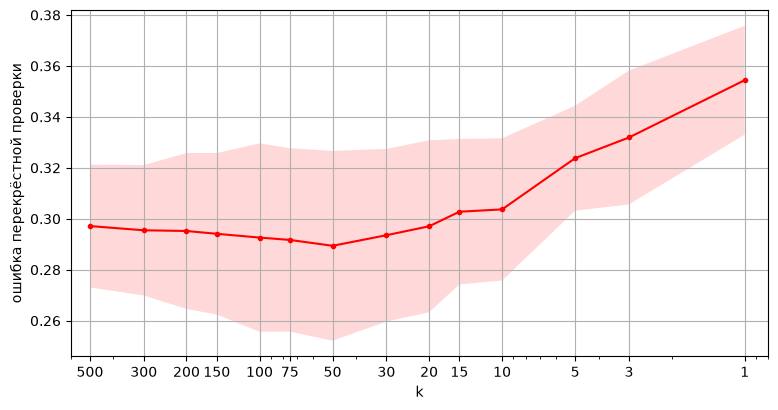

In [34]:
plt.figure(figsize=(9, 4.5))
plt.plot(k_arr, cv_err, "r.-")
plt.fill_between(k_arr, cv_err - cv_std, cv_err + cv_std, alpha=0.15, facecolor="r")
plt.xscale("log"); plt.xticks(k_arr, k_arr)
plt.xlim([max(k_arr) * 1.2, 0.8])   # ось развёрнута: вправо растёт сложность модели
plt.xlabel("k"); plt.ylabel("ошибка перекрёстной проверки")
plt.grid()

In [35]:
knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(X_train_s, y_train)
errors(knn)
print(classification_report(y_test, knn.predict(X_test_s), target_names=["обычный", "суперхост"], digits=3))

обучающая выборка: ошибка 0.2011
[[4531 1230]
 [ 950 4132]]

тестовая выборка: ошибка 0.3520
[[1202  573]
 [ 864 1443]]



              precision    recall  f1-score   support

     обычный      0.582     0.677     0.626      1775
   суперхост      0.716     0.625     0.668      2307

    accuracy                          0.648      4082
   macro avg      0.649     0.651     0.647      4082
weighted avg      0.658     0.648     0.649      4082



**Проверка выбора нормализации** (п. 7): ошибка перекрёстной проверки kNN при том же $k$, если стандартизовать
и бинарные, и dummy-признаки:

In [36]:
X_all_std = (X_train_n - X_train_n.mean()) / X_train_n.std().replace(0, 1)
err_all = 1 - cross_val_score(KNeighborsClassifier(n_neighbors=best_k), X_all_std.to_numpy(), y_train,
                              groups=groups_train, cv=cv, n_jobs=-1).mean()
print(f"dummy-признаки 0/1: {cv_err[k_arr.index(best_k)]:.4f};  все признаки стандартизованы: {err_all:.4f}")

dummy-признаки 0/1: 0.2894;  все признаки стандартизованы: 0.3405


- Меньше всего ошибка перекрёстной проверки при **$k = 50$** (28.9 %).
  * При $k = 1$ модель переобучается (35.4 %), при $k = 3$–5 ошибка тоже заметно выше (32–33 %).
  * При больших $k$ ошибка снова растёт (29.7 % при $k = 500$): модель слишком сглаживает и недообучается.
  * Разброс по блокам большой (±2–4 %): ошибка сильно зависит от того, какие хозяева попали в блок.
- С $k = 50$ ошибка на обучающей выборке 20.1 %, на тестовой 35.2 % (было 36.8 % при $k = 10$). Найдено 1 443
  суперхоста из 2 307 (63 %), ложных суперхостов 573.
  * Для класса «суперхост» precision 0.72, recall 0.63.
  * Тестовая ошибка выше ошибки перекрёстной проверки: в тестовую выборку целиком попали два крупнейших
    хозяина-суперхоста (227 и 150 объявлений). Их объявления почти одинаковы, и модель ошибается на них
    «пачкой».
- **Нормализация.** Если стандартизовать и dummy-признаки, ошибка перекрёстной проверки при том же $k$ растёт с
  28.9 % до 34.1 %. Это подтверждает решение из п. 7: после стандартизации редкие категории (районы, типы
  объектов) получают огромные значения и начинают определять расстояние.

In [37]:
def summary(model, cv_error=None):
    # ошибка на train, на перекрёстной проверке (по хозяевам), на test, найдено суперхостов (TP), ложных (FP)
    if cv_error is None:
        cv_error = 1 - cross_val_score(model, X_train_s, y_train, groups=groups_train, cv=cv, n_jobs=-1).mean()
    cm = confusion_matrix(y_test, model.predict(X_test_s))
    return [np.mean(y_train != model.predict(X_train_s)), cv_error,
            np.mean(y_test != model.predict(X_test_s)), cm[1, 1], cm[0, 1]]

results = {}
results["kNN, k = %d" % best_k] = summary(knn, cv_err[k_arr.index(best_k)])

## 10. Другие классификаторы

Кроме ошибок на обучающей и тестовой выборках, для каждого метода считаем ошибку перекрёстной проверки по
хозяевам. Тестовая выборка одна, и в неё целиком попадают крупные хозяева. Ошибка, усреднённая по 5 разным
наборам хозяев, надёжнее.

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn import ensemble

models = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "SVC": SVC(gamma="scale"),
    "Random Forest": ensemble.RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees": ensemble.ExtraTreesClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE),
    "AdaBoost": ensemble.AdaBoostClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "GBT": ensemble.GradientBoostingClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Neural Network (64, 32), ReLU": MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-3,
                                                   early_stopping=True, max_iter=500, random_state=RANDOM_STATE),
}
for name, model in models.items():
    t = time.time()
    model.fit(X_train_s, y_train)
    print(f"=== {name}  ({time.time() - t:.0f} c)")
    errors(model)
    results[name] = summary(model)

=== Logistic Regression  (0 c)
обучающая выборка: ошибка 0.2527
[[4412 1349]
 [1391 3691]]

тестовая выборка: ошибка 0.3097
[[1263  512]
 [ 752 1555]]



=== SVC  (3 c)


обучающая выборка: ошибка 0.1256
[[5103  658]
 [ 704 4378]]



тестовая выборка: ошибка 0.3572
[[1287  488]
 [ 970 1337]]



=== Random Forest  (1 c)
обучающая выборка: ошибка 0.0000
[[5761    0]
 [   0 5082]]



...

=== AdaBoost  (7 c)


обучающая выборка: ошибка 0.2279
[[4655 1106]
 [1365 3717]]



тестовая выборка: ошибка 0.3682
[[1342  433]
 [1070 1237]]



=== GBT  (15 c)
обучающая выборка: ошибка 0.0884
[[5307  454]
 [ 504 4578]]

тестовая выборка: ошибка 0.3599
[[1298  477]
 [ 992 1315]]



=== Neural Network (64, 32), ReLU  (2 c)
обучающая выборка: ошибка 0.0982
[[5212  549]
 [ 516 4566]]

тестовая выборка: ошибка 0.3849
[[1202  573]
 [ 998 1309]]



### Значимость признаков (Random Forest)

Feature ranking:
 1. feature 'host_listings_count' (0.048228)
 2. feature 'estimated_occupancy_l365d' (0.045108)
 3. feature 'estimated_revenue_l365d' (0.044814)
 4. feature 'review_scores_rating' (0.043816)
 5. feature 'number_of_reviews_ltm' (0.040902)
 6. feature 'calculated_host_listings_count' (0.039266)
 7. feature 'calculated_host_listings_count_entire_homes' (0.038691)
 8. feature 'host_months' (0.035359)
 9. feature 'user_months' (0.033152)
10. feature 'reviews_per_month' (0.031646)
11. feature 'review_scores_cleanliness' (0.031329)
12. feature 'review_scores_value' (0.030521)
13. feature 'days_last_review' (0.029755)
14. feature 'number_of_reviews' (0.028268)
15. feature 'review_scores_accuracy' (0.028161)
16. feature 'n_amenities' (0.027237)
17. feature 'review_scores_communication' (0.024158)
18. feature 'number_of_reviews_ly' (0.023638)
19. feature 'longitude' (0.022712)
20. feature 'latitude' (0.022340)


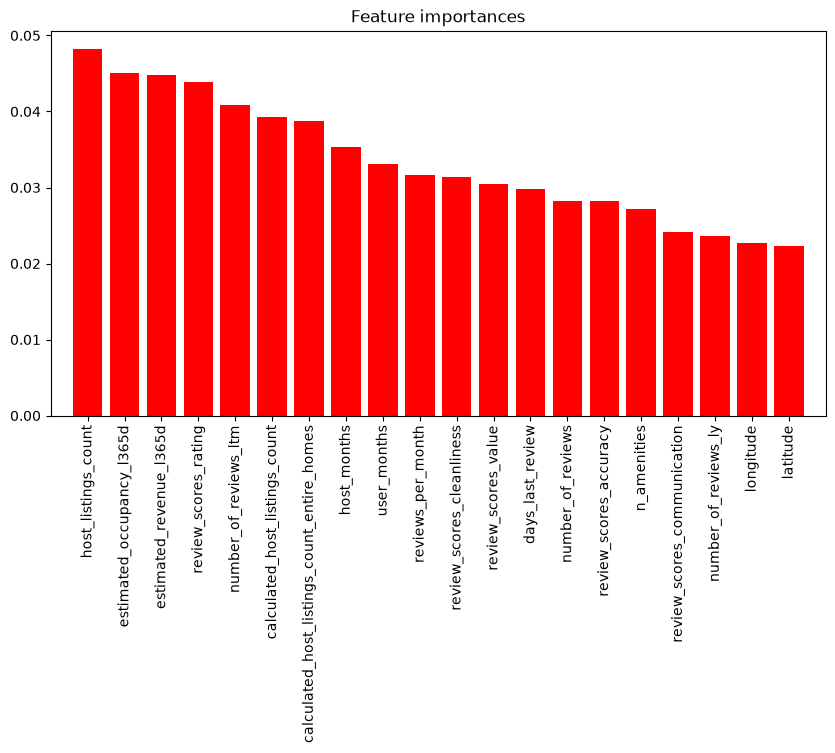

In [39]:
rf = models["Random Forest"]
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(20):
    print("%2d. feature '%5s' (%f)" % (f + 1, feature_names[indices[f]], importances[indices[f]]))

d_first = 20
plt.figure(figsize=(10, 5))
plt.title("Feature importances")
plt.bar(range(d_first), importances[indices[:d_first]], align="center", color="r")
plt.xticks(range(d_first), feature_names[indices[:d_first]], rotation=90)
plt.xlim([-1, d_first])
pass

### Сравнение

In [40]:
print("Всего суперхостов в тестовой выборке:", y_test.sum(), " обычных хозяев:", (y_test == 0).sum())
pd.DataFrame(results, index=["err_train", "err_cv", "err_test", "найдено суперхостов", "ложных суперхостов"]).T \
    .astype({"найдено суперхостов": int, "ложных суперхостов": int}).sort_values("err_cv").round(4)

Всего суперхостов в тестовой выборке: 2307  обычных хозяев: 1775


,err_train,err_cv,err_test,найдено суперхостов,ложных суперхостов
GBT,0.0884,0.2465,0.3599,1315,477
Random Forest,0.0000,0.2557,0.3577,1253,406
Extra Trees,0.0000,0.2559,0.3332,1348,401
SVC,0.1256,0.2631,0.3572,1337,488
"Neural Network (64, 32), ReLU",0.0982,0.2738,0.3849,1309,573
AdaBoost,0.2279,0.2830,0.3682,1237,433
"kNN, k = 50",0.2011,0.2894,0.3520,1443,573
Logistic Regression,0.2527,0.2984,0.3097,1555,512


- **По ошибке перекрёстной проверки** лучше всех ансамбли деревьев: GBT (24.7 %), Random Forest и Extra Trees
  (25.6 %). Затем SVC (26.3 %), нейросеть (27.4 %), AdaBoost (28.3 %), kNN (28.9 %) и логистическая регрессия
  (29.8 %).
- **На тестовой выборке** порядок другой: лучше всех логистическая регрессия (31.0 %) и Extra Trees (33.3 %), kNN
  35.2 %, бустинг и лес около 36 %. Тестовая выборка одна и содержит крупнейших хозяев. По «хозяйским» признакам
  ансамбли деревьев выучили, что очень крупная управляющая компания обычно не суперхост, и на объявлениях этих
  двух хозяев ошибаются. Поэтому для сравнения методов надёжнее перекрёстная проверка по 5 разным наборам хозяев.
- У Random Forest и Extra Trees ошибка на обучающей выборке 0: деревья запоминают обучающую выборку. На
  перекрёстной проверке они всё равно лучше kNN. Логистическая регрессия почти не переобучается (25.3 % на
  обучающей выборке, 29.8 % на перекрёстной проверке).
- Меньше всего ложных суперхостов у Extra Trees (401) и Random Forest (406): ансамбли деревьев осторожнее
  присваивают статус. Для нашего сценария (п. 0), где ложный суперхост хуже, это плюс. Больше всего суперхостов
  находит логистическая регрессия (1 555 из 2 307).
- По значимости признаков (Random Forest) важнее всего число объявлений хозяина, расчётная занятость и выручка,
  оценка гостей, отзывы за год и стаж хозяина. Это совпадает с корреляционным анализом из п. 3.

## 11. Несбалансированность классов

In [41]:
print("доля суперхостов: train = %.3f, test = %.3f" % (y_train.mean(), y_test.mean()))

доля суперхостов: train = 0.469, test = 0.565


Суперхостов 47 % в обучающей выборке и 57 % в тестовой. Классы почти сбалансированы, поэтому специально бороться
с несбалансированностью (веса классов, сдвиг порога, дублирование объектов редкого класса) не нужно. Доля ошибок
здесь адекватно отражает качество: «классификатор», который всегда отвечает одно и то же, ошибается почти в
половине случаев.

## 12. Исключение коррелированных переменных

Сильно коррелированные признаки несут почти одну и ту же информацию. Для kNN она учитывается в расстоянии несколько
раз и «перевешивает» остальные признаки. Для линейных моделей это мультиколлинеарность и неустойчивые
коэффициенты. Избыточная информация вообще — один из источников переобучения.

Найдём пары количественных признаков с $|r| > 0.9$ (на обучающей выборке, после логарифмирования) и удалим из
каждой пары один признак.

In [42]:
c_n = X_train_n[scale_columns].corr().abs()
high = c_n.where(np.triu(np.ones(c_n.shape, dtype=bool), k=1)).stack().dropna()
high = high[high > 0.9].sort_values(ascending=False)
high.round(3)

maximum_nights                  maximum_maximum_nights                         1.000
minimum_nights                  minimum_minimum_nights                         1.000
availability_90                 availability_eoy                               0.996
maximum_nights                  maximum_nights_avg_ntm                         0.979
maximum_maximum_nights          maximum_nights_avg_ntm                         0.979
minimum_maximum_nights          maximum_nights_avg_ntm                         0.969
availability_60                 availability_90                                0.956
number_of_reviews_ltm           estimated_occupancy_l365d                      0.942
availability_60                 availability_eoy                               0.940
maximum_nights                  minimum_maximum_nights                         0.930
minimum_maximum_nights          maximum_maximum_nights                         0.930
calculated_host_listings_count  calculated_host_listings_count_en

In [43]:
to_drop = []
for (a, b), r in high.items():
    if a not in to_drop and b not in to_drop:
        to_drop.append(b)
print("удаляем:", to_drop)

keep = [i for i, c in enumerate(feature_names) if c not in to_drop]
X_train_r, X_test_r = X_train_s[:, keep], X_test_s[:, keep]

grid_r = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": k_arr}, cv=cv, n_jobs=-1)
grid_r.fit(X_train_r, y_train, groups=groups_train)
knn_r = KNeighborsClassifier(n_neighbors=grid_r.best_params_["n_neighbors"]).fit(X_train_r, y_train)
print("признаков:", X_train_s.shape[1], "->", X_train_r.shape[1], ", k =", grid_r.best_params_["n_neighbors"])
print("kNN: err_cv = %.4f, err_test = %.4f" % (1 - grid_r.best_score_, np.mean(y_test != knn_r.predict(X_test_r))))

lr_r = LogisticRegression(max_iter=5000).fit(X_train_r, y_train)
lr_cv = 1 - cross_val_score(LogisticRegression(max_iter=5000), X_train_r, y_train, groups=groups_train, cv=cv).mean()
print("Logistic Regression: err_cv = %.4f, err_test = %.4f" % (lr_cv, np.mean(y_test != lr_r.predict(X_test_r))))

удаляем: ['maximum_maximum_nights', 'minimum_minimum_nights', 'availability_eoy', 'maximum_nights_avg_ntm', 'availability_90', 'estimated_occupancy_l365d', 'minimum_maximum_nights', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count', 'minimum_nights_avg_ntm']


признаков: 111 -> 101 , k = 100
kNN: err_cv = 0.2814, err_test = 0.3278


Logistic Regression: err_cv = 0.2972, err_test = 0.3119


Удалено 10 признаков (111 → 101): дубли минимального и максимального срока, `availability_90` и
`availability_eoy`, два счётчика объявлений хозяина и `estimated_occupancy_l365d`, почти совпадающий с числом
отзывов за год.

- **kNN стал лучше:** ошибка перекрёстной проверки 28.9 % → 28.1 % (оптимум при $k = 100$), на тестовой выборке
  35.2 % → 32.8 %. Повторяющаяся информация больше не учитывается в расстоянии несколько раз.
- **Логистическая регрессия практически не изменилась:** 29.8 % → 29.7 % на перекрёстной проверке, 31.0 % → 31.2 %
  на тесте. Встроенная регуляризация и так справлялась с коррелированными признаками.

## 13. Выводы

1. Решалась задача бинарной классификации: по объявлению Airbnb в Афинах предсказать, является ли хозяин
   суперхостом. Положительный класс — суперхост, классы почти сбалансированы (47 %).
2. Утечки ответа в признаках нет: средняя оценка ≥ 4.8 (ближайший к определению статуса признак) сама по себе
   статус не определяет. Метка принадлежит хозяину, поэтому выборки и блоки перекрёстной проверки разбивались по
   хозяевам.
3. С суперхостом сильнее всего связаны активность (занятость, свежие отзывы), оценки гостей и число удобств.
   Отрицательно связаны давность последнего отзыва и большое число объявлений у хозяина. Связь каждого отдельного
   признака слабая ($|r| \le 0.36$).
4. Невозможных значений нет. Явно ошибочные значения (цены в тысячи евро за ночь, десятки спален) удалены из
   обучающей выборки (1.9 % строк). Пропуски в отзывах и цене неслучайны, поэтому превращены в признаки-индикаторы,
   остальные заполнены медианой и модой. Номинальные признаки бинаризованы, количественные с длинным хвостом
   прологарифмированы и нормализованы, dummy-признаки оставлены 0/1 (проверено: так ошибка kNN на 5 п. п. меньше).
5. kNN с $k = 50$, выбранным перекрёстной проверкой: ошибка 20.1 % на обучающей выборке, 28.9 % на перекрёстной
   проверке, 35.2 % на тестовой. Найдено 63 % суперхостов. После удаления коррелированных признаков — 28.1 % и
   32.8 %.
6. Лучший метод по перекрёстной проверке — градиентный бустинг (24.7 %), затем Random Forest и Extra Trees (25.6 %).
   kNN (28.9 %) и логистическая регрессия (29.8 %) уступают.
7. Ошибка на единственной тестовой выборке ненадёжна: в неё целиком попали крупнейшие хозяева, и на ней лучшей
   оказалась логистическая регрессия (31.0 %). Выбирать метод лучше по перекрёстной проверке по хозяевам.
8. Ошибка около 25–30 % — разумный результат для этих данных: двух официальных критериев статуса (доля ответов и
   отмены) в датасете нет.